# Aula 10 – Fundamentos de avaliação: generalização, overfitting e divisão de dados

## Versão do aluno

### Objetivo da aula
Montar um experimento de avaliação de modelos e interpretar como a divisão dos dados influencia a confiabilidade das previsões.

### Instruções
Complete as células indicadas e registre suas interpretações.  
Use gráficos para comparar os resultados.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- divisão dos dados;
- pipeline de pré-processamento;
- regressão e métricas;
- validação cruzada.


In [38]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
print('Todas as bibliotecas importadas com sucesso!')

Todas as bibliotecas importadas com sucesso!


## 2. Leitura da base

Leia o arquivo `dados_aula10_avaliacao_modelos_industrial.csv` e mostre as primeiras linhas.


In [39]:
# Complete aqui
df = pd.read_csv('dados_aula10_avaliacao_modelos_industrial.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,leituras_invalidas,horas_operacao_bomba,vazao_real_l_min
0,AVL_0001,Linha_A,Noite,Acido,NaN,3.50,2.57,69.48,21.58,1.97,2,228.0,69.21
1,AVL_0002,Linha_B,Tarde,Acido,34.58,4.60,2.60,41.92,23.34,3.15,5,366.2,53.74
2,AVL_0003,Linha_C,Manhã,Solvente,52.54,2.84,2.86,49.19,24.31,3.23,1,326.8,38.23
3,AVL_0004,Linha_A,Manhã,Base,57.71,3.46,2.67,56.41,25.81,0.51,3,392.5,50.74
4,AVL_0005,Linha_B,Noite,Base,43.61,4.63,2.55,49.88,23.25,2.41,2,215.4,57.10


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas.


In [40]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())

Dimensão da base: (332, 13)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
leituras_invalidas        int64
horas_operacao_bomba    float64
vazao_real_l_min        float64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 7
temperatura_c           7
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        9
leituras_invalidas      0
horas_operacao_bomba    0
vazao_real_l_min        0
dtype: int64

Duplicatas: 12


**Registro do aluno:**  
- dimensão da base: 332 x 13
- tipos de dados: object e float64
- valores faltantes: 31
- duplicatas: 12

## 4. Limpeza básica

Remova as duplicatas da base.


In [41]:
# Complete aqui
df = df.drop_duplicates().copy()
print(df.shape)

(320, 13)


## 5. Definição de X e y

Separe:
- `X`: variáveis de entrada;
- `y`: variável-alvo `vazao_real_l_min`.

**Pergunta:** por que `id_registro` não deve ser usado como preditora?


In [42]:
# Complete aqui
X = df.drop(columns=['id_registro', 'vazao_real_l_min'])
y = df['vazao_real_l_min']

print(X.shape)
print(y.shape)

(320, 11)
(320,)


**Resposta do aluno:** Porque `id_registro` é apenas uma variável que identifica a posição do registro feito, isso, na prática, não é uma informação que vai definir o funcionamento dos equipamentos.


## 6. Divisão em treino, validação e teste

Faça a divisão em duas etapas:
1. treino+validação e teste;
2. treino e validação.


In [43]:
# Complete aqui
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42
)

print('Treino:', X_train.shape, y_train.shape)
print('Validação:', X_val.shape, y_val.shape)
print('Teste:', X_test.shape, y_test.shape)

Treino: (192, 11) (192,)
Validação: (64, 11) (64,)
Teste: (64, 11) (64,)


**Resposta do aluno:**  

- Treino: (192, 11) (192,)
- Validação: (64, 11) (64,)
- Teste: (64, 11) (64,)



## 7. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [44]:
# Complete aqui
colunas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

colunas_numericas, colunas_categoricas

(['temperatura_c',
  'pressao_bar',
  'vibracao_mm_s',
  'abertura_valvula_pct',
  'consumo_energia_kwh',
  'tempo_resposta_s',
  'leituras_invalidas',
  'horas_operacao_bomba'],
 ['linha', 'turno', 'produto'])

## 8. Criação de três modelos para comparação

Nesta aula, crie três situações:
1. **Regressão Linear**
2. **Árvore de Decisão Complexa**
3. **Árvore de Decisão Controlada**

### Objetivo
Comparar:
- um modelo mais simples;
- um modelo muito flexível;
- um modelo intermediário.


In [45]:
# Complete aqui
modelo_linear = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LinearRegression())
])

modelo_arvore_complexa = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeRegressor(random_state=42))
])

modelo_arvore_controlada = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeRegressor(max_depth=4, min_samples_leaf=8, random_state=42))
])

## 9. Treino dos modelos

Treine os três modelos com o conjunto de treino.


In [46]:
# Complete aqui
modelo_linear.fit(X_train, y_train)
modelo_arvore_complexa.fit(X_train, y_train)
modelo_arvore_controlada.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 10. Predições em treino e validação

Gere previsões para treino e validação dos três modelos.


In [47]:
# Complete aqui
pred_train_linear = modelo_linear.predict(X_train)
pred_val_linear = modelo_linear.predict(X_val)

pred_train_arvore_complexa = modelo_arvore_complexa.predict(X_train)
pred_val_arvore_complexa = modelo_arvore_complexa.predict(X_val)

pred_train_arvore_controlada = modelo_arvore_controlada.predict(X_train)
pred_val_arvore_controlada = modelo_arvore_controlada.predict(X_val)

## 11. Cálculo das métricas

Use MAE, RMSE e R² para os três modelos.


### Observação importante sobre as métricas desta aula

Usamos **MAE**, **RMSE** e **R²** para os três modelos porque todos estão sendo usados como **modelos de regressão** com alvo numérico contínuo (`vazao_real_l_min`).

### Regra principal
- alvo **numérico contínuo** → métricas de regressão;
- alvo **categórico** → métricas de classificação.


In [48]:
# Complete aqui
def calcular_metricas(y_real, y_pred):
  mae = mean_absolute_error(y_real, y_pred)
  rmse = np.sqrt(mean_squared_error(y_real, y_pred))
  r2 = r2_score(y_real, y_pred)
  return mae, rmse, r2

resultados = pd.DataFrame({
    'Modelo': [
        'Linear', 'Linear',
        'Árvore Complexa', 'Árvore Complexa',
        'Árvore Controlada', 'Árvore Controlada'
    ],
    'Conjunto': [
        'Treino', 'Validação',
        'Treino', 'Validação',
        'Treino', 'Validação'
    ],
    'MAE': [
        calcular_metricas(y_train, pred_train_linear)[0],
        calcular_metricas(y_val, pred_val_linear)[0],
        calcular_metricas(y_train, pred_train_arvore_complexa)[0],
        calcular_metricas(y_val, pred_val_arvore_complexa)[0],
        calcular_metricas(y_train, pred_train_arvore_controlada)[0],
        calcular_metricas(y_val, pred_val_arvore_controlada)[0]
    ],
    'RMSE': [
        calcular_metricas(y_train, pred_train_linear)[1],
        calcular_metricas(y_val, pred_val_linear)[1],
        calcular_metricas(y_train, pred_train_arvore_complexa)[1],
        calcular_metricas(y_val, pred_val_arvore_complexa)[1],
        calcular_metricas(y_train, pred_train_arvore_controlada)[1],
        calcular_metricas(y_val, pred_val_arvore_controlada)[1]
    ],
    'R2': [
        calcular_metricas(y_train, pred_train_linear)[2],
        calcular_metricas(y_val, pred_val_linear)[2],
        calcular_metricas(y_train, pred_train_arvore_complexa)[2],
        calcular_metricas(y_val, pred_val_arvore_complexa)[2],
        calcular_metricas(y_train, pred_train_arvore_controlada)[2],
        calcular_metricas(y_val, pred_val_arvore_controlada)[2]
    ]
}).round(4)

resultados

,Modelo,Conjunto,MAE,RMSE,R2
0,Linear,Treino,3.7081,4.8101,0.8731
1,Linear,Validação,3.4981,4.4844,0.9008
2,Árvore Complexa,Treino,0.0000,0.0000,1.0000
3,Árvore Complexa,Validação,7.6287,10.0856,0.4981
4,Árvore Controlada,Treino,4.7891,6.0312,0.8005
5,Árvore Controlada,Validação,7.0556,9.2465,0.5782


## 12. Visualização comparativa das métricas

Crie gráficos para comparar treino e validação nos três modelos.


In [49]:
# Complete aqui
res_mae = resultados.pivot(index='Modelo', columns='Conjunto', values='MAE')
res_rmse = resultados.pivot(index='Modelo', columns='Conjunto', values='RMSE')
res_r2 = resultados.pivot(index='Modelo', columns='Conjunto', values='R2')

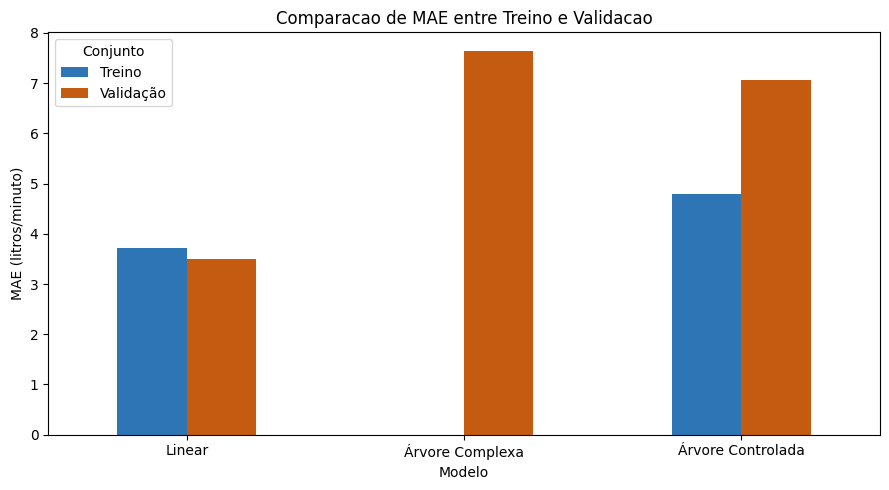

In [50]:
# Gere o gráfico de MAE aqui
ax = res_mae.plot(kind='bar', rot=0, figsize=(9, 5), title='Comparacao de MAE entre Treino e Validacao', color=['#2E75B6', '#C55A11'])
ax.set_ylabel('MAE (litros/minuto)')
ax.set_xlabel('Modelo')
plt.tight_layout()
plt.show()

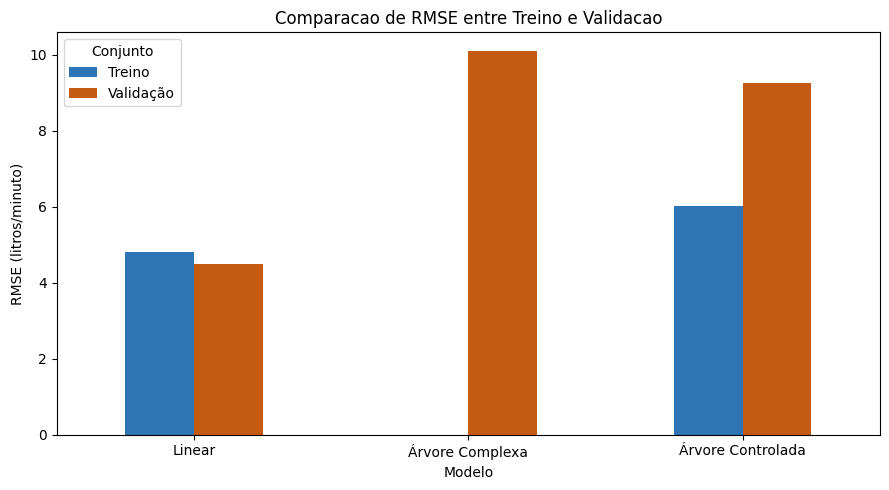

In [51]:
# Gere o gráfico de RMSE aqui
ax = res_rmse.plot(kind='bar', rot=0, figsize=(9, 5), title='Comparacao de RMSE entre Treino e Validacao', color=['#2E75B6', '#C55A11'])
ax.set_ylabel('RMSE (litros/minuto)')
ax.set_xlabel('Modelo')
plt.tight_layout()
plt.show()

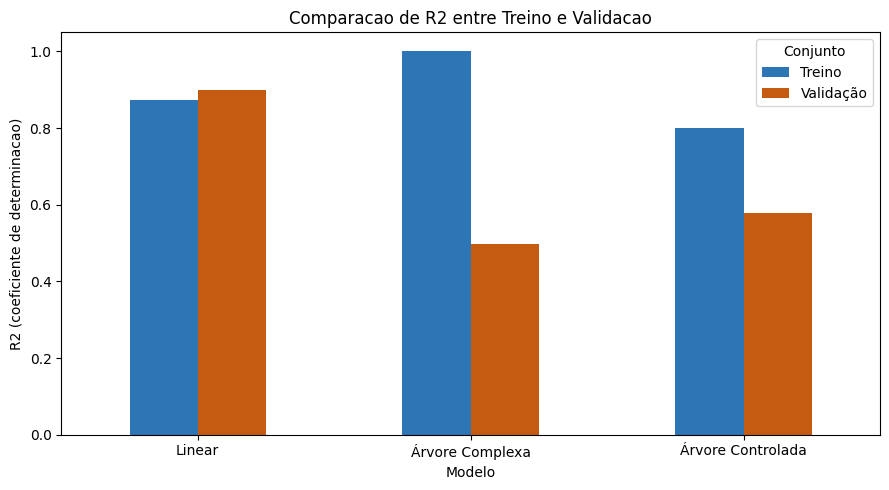

In [52]:
# Gere o gráfico de R² aqui
ax = res_r2.plot(kind='bar', rot=0, figsize=(9, 5), title='Comparacao de R2 entre Treino e Validacao', color=['#2E75B6', '#C55A11'])
ax.set_ylabel('R2 (coeficiente de determinacao)')
ax.set_xlabel('Modelo')
plt.tight_layout()
plt.show()

## 13. Interpretação: underfitting, overfitting e generalização

Use os resultados para identificar:
- qual modelo parece simples demais;
- qual modelo parece ajustado demais ao treino;
- qual modelo parece mais equilibrado.


**Interpretação do aluno:**  
- Possível underfitting: Árvore Controlada
- Possível overfitting:  Árvore Complexa
- Melhor generalização: Linear


## 14. Viés e variância

Relacione os modelos aos conceitos:
- alto viés;
- alta variância;
- equilíbrio entre ambos.


**Resposta do aluno:**  
- Alto viés: Linear
- Alta variância: Árvore Complexa
- Melhor equilíbrio: Árvore Controlada


## 15. Validação cruzada (k-fold)

Aplique validação cruzada com 5 folds para os três modelos.


In [53]:
# Complete aqui
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_linear = cross_val_score(modelo_linear, X_temp, y_temp, cv=kf, scoring='r2')
cv_arvore_complexa = cross_val_score(modelo_arvore_complexa, X_temp, y_temp, cv=kf, scoring='r2')
cv_arvore_controlada = cross_val_score(modelo_arvore_controlada, X_temp, y_temp, cv=kf, scoring='r2')

print(cv_linear)
print(cv_arvore_complexa)
print(cv_arvore_controlada)

[0.89343797 0.87445245 0.85028666 0.85210598 0.82894282]
[0.29183209 0.48138866 0.43933071 0.55435843 0.61326068]
[0.4548478  0.63879246 0.4362074  0.50103111 0.64455785]


## 16. Visualização da validação cruzada

Monte uma tabela com os folds e crie um gráfico comparando os três modelos.


In [58]:
# Complete aqui
cv_df = pd.DataFrame({
    'Fold': [1, 2, 3, 4, 5],
    'Linear': cv_linear,
    'Arvore Complexa': cv_arvore_complexa,
    'Arvore Controlada': cv_arvore_controlada
})

cv_df

,Fold,Linear,Arvore Complexa,Arvore Controlada
0,1,0.893438,0.291832,0.454848
1,2,0.874452,0.481389,0.638792
2,3,0.850287,0.439331,0.436207
3,4,0.852106,0.554358,0.501031
4,5,0.828943,0.613261,0.644558


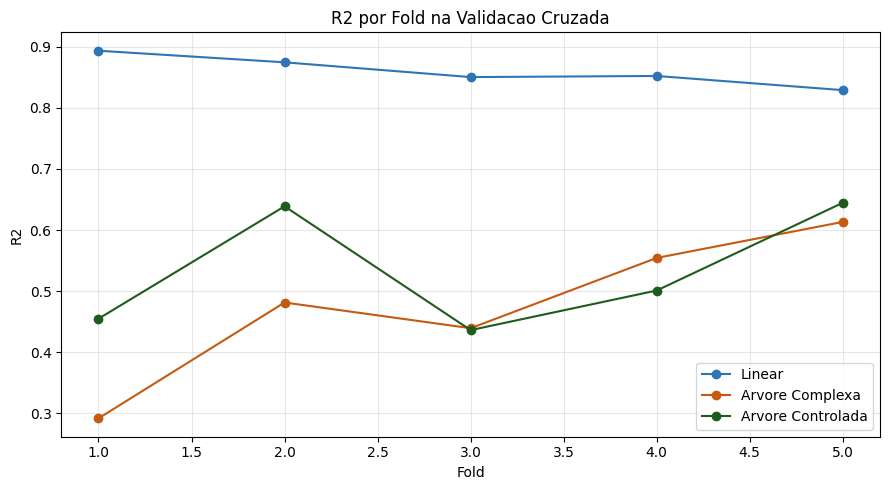

In [59]:
# Gere o gráfico aqui
plt.figure(figsize=(9, 5))
plt.plot(cv_df['Fold'], cv_df['Linear'], marker='o', label='Linear', color='#2E75B6')
plt.plot(cv_df['Fold'], cv_df['Arvore Complexa'], marker='o', label='Arvore Complexa', color='#C55A11')
plt.plot(cv_df['Fold'], cv_df['Arvore Controlada'], marker='o', label='Arvore Controlada', color='#1E5C1E')
plt.title('R2 por Fold na Validacao Cruzada')
plt.xlabel('Fold')
plt.ylabel('R2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Como avaliar se houve boa generalização

Use treino, validação, teste e validação cruzada para decidir se o modelo generalizou bem.

### Referências práticas
- métricas relativamente próximas entre treino, validação e teste;
- **RMSE** não muito acima do **MAE**;
- **R²** como referência pedagógica:
  - abaixo de 0,50: fraco
  - entre 0,50 e 0,70: moderado
  - entre 0,70 e 0,85: bom
  - acima de 0,85: muito bom, desde que coerente entre os conjuntos

### Sinais importantes
- treino muito melhor que validação/teste → possível **overfitting**
- treino e validação ambos fracos → possível **underfitting**
- folds muito instáveis → possível falta de robustez


## 17. Avaliação final no conjunto de teste

Compare os três modelos no teste.


In [62]:
# Complete aqui
pred_test_linear = modelo_linear.predict(X_test)
pred_test_arvore_complexa = modelo_arvore_complexa.predict(X_test)
pred_test_arvore_controlada = modelo_arvore_controlada.predict(X_test)

teste_resultados = pd.DataFrame({
    'Modelo': ['Linear', 'Árvore Complexa', 'Árvore Controlada'],
    'MAE_teste': [
      calcular_metricas(y_test, pred_test_linear)[0],
      calcular_metricas(y_test, pred_test_arvore_complexa)[0],
      calcular_metricas(y_test, pred_test_arvore_controlada)[0]
    ],
    'RMSE_teste': [
      calcular_metricas(y_test, pred_test_linear)[1],
      calcular_metricas(y_test, pred_test_arvore_complexa)[1],
      calcular_metricas(y_test, pred_test_arvore_controlada)[1]
    ],
    'R2_teste': [
      calcular_metricas(y_test, pred_test_linear)[2],
      calcular_metricas(y_test, pred_test_arvore_complexa)[2],
      calcular_metricas(y_test, pred_test_arvore_controlada)[2]
    ]
}).round(4)

teste_resultados

,Modelo,MAE_teste,RMSE_teste,R2_teste
0,Linear,3.5789,4.3775,0.8970
1,Árvore Complexa,6.4211,7.9619,0.6593
2,Árvore Controlada,6.2677,7.9279,0.6622


## 18. Interpretação final

Escreva:
- qual modelo mostrou sinais de underfitting;
- qual modelo mostrou sinais de overfitting;
- qual modelo foi mais confiável para generalização.


**Resposta do aluno:**  
- Underfitting:  Árvore Controlada
- Overfitting:  Árvore Complexa
- Melhor generalização: Linear


## 19. Exportação dos resultados

Salve as tabelas principais do experimento.


In [63]:
# Complete aqui
resultados.to_csv('metricas_treino_validacao_aula10_revisado.csv', index=False)
teste_resultados.to_csv('metricas_teste_aula10_revisado.csv', index=False)
cv_df.to_csv('validacao_cruzada_aula10_revisado.csv', index=False)
print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- identificou sinais de underfitting e overfitting;
- relacionou os modelos a viés e variância;
- aplicou treino, validação, teste e validação cruzada com coerência.


## Síntese interpretativa dos resultados

A análise dos resultados obtidos evidencia, de forma aplicada, os conceitos de **generalização**, **overfitting**, **underfitting**, **viés** e **variância** no contexto da avaliação de modelos preditivos.

A **Regressão Linear** apresentou o comportamento mais consistente entre os modelos analisados, com métricas satisfatórias e relativamente estáveis nos conjuntos de **treino**, **validação** e **teste**, além de desempenho coerente na **validação cruzada**. Tal resultado indica adequada capacidade de generalização, demonstrando que o modelo conseguiu representar o padrão predominante dos dados sem excessivo ajuste ao conjunto de treinamento.

A **Árvore de Decisão Complexa**, por sua vez, apresentou desempenho extremamente elevado no conjunto de treino, porém com redução expressiva de desempenho nos conjuntos de validação, teste e folds da validação cruzada. Esse comportamento é característico de **overfitting**, situação em que o modelo se ajusta de forma excessiva aos dados utilizados no treinamento, comprometendo sua capacidade de generalização para novos dados.

A **Árvore de Decisão Controlada** apresentou desempenho intermediário, indicando que a restrição de complexidade contribuiu para reduzir o sobreajuste observado na árvore complexa. Ainda assim, seus resultados não superaram o equilíbrio apresentado pela regressão linear.

Dessa forma, os resultados reforçam que a avaliação de modelos não deve se restringir ao desempenho obtido no conjunto de treino. A análise conjunta de **treino**, **validação**, **teste** e **validação cruzada** é fundamental para verificar a robustez do modelo e sua aplicabilidade em situações reais, favorecendo a seleção de soluções com melhor equilíbrio entre ajuste, estabilidade e capacidade preditiva.